<a href="https://colab.research.google.com/github/Kathir-20/Introduction-to-AI-Module-Electronics-and-Computer-Engineering---2026-2027/blob/main/AS1%20-%20CSY%202082.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO

from google.colab import auth
from google.auth import default
from google.auth.transport.requests import AuthorizedSession

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
def load_data():

    # Connect to Google Drive
    auth.authenticate_user()

    credentials, _ = default()
    drive_session = AuthorizedSession(credentials)

    # Excel file ID from Google Drive
    file_id = "17Hj53tG2U3ib3TfrslGthGCyuqbdFAJ3"

    download_url = f"https://www.googleapis.com/drive/v3/files/{file_id}?alt=media"

    try:
        print("Loading the house price dataset...")

        response = drive_session.get(download_url)
        response.raise_for_status()

        # Read the Excel file
        data = pd.read_excel(BytesIO(response.content), sheet_name=0)

        print("Dataset loaded successfully!")
        print(f"Number of rows: {data.shape[0]}")
        print(f"Number of columns: {data.shape[1]}")

        return data

    except Exception as error:
        print("There was a problem loading the dataset:", error)
        raise

In [3]:
df = load_data()

display(df.head()) # It sample code for testing data  table.

Loading the house price dataset...
Dataset loaded successfully!
Number of rows: 30006
Number of columns: 15


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,895900,"3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000,"1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900,"1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,959000,"1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,532000.0,"6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,83500,440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,52000.0,"251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30006 entries, 0 to 30005
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Price           30006 non-null  object 
 1   Sqr Ft          27786 non-null  object 
 2   Longitude       30006 non-null  float64
 3   Latitude        30006 non-null  float64
 4   Lot Size        25490 non-null  object 
 5   Beds            27420 non-null  float64
 6   Bath            27496 non-null  float64
 7   Year Built      26258 non-null  float64
 8   Last Sold Year  14213 non-null  float64
 9   Last Sold For   14213 non-null  float64
 10  Address         30006 non-null  object 
 11  City            30006 non-null  object 
 12  State           30006 non-null  object 
 13  Zipcode         30003 non-null  float64
 14  Address Full    30006 non-null  object 
dtypes: float64(8), object(7)
memory usage: 3.4+ MB

Missing values in each column:


,0
Price,0
Sqr Ft,2220
Longitude,0
Latitude,0
Lot Size,4516
Beds,2586
Bath,2510
Year Built,3748
Last Sold Year,15793
Last Sold For,15793



Statistical summary:


,Longitude,Latitude,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,30006.000000,30006.000000,27420.000000,27496.000000,26258.000000,14213.000000,1.421300e+04,30003.000000
mean,-95.167341,36.158007,3.288658,2.578688,1973.140224,2011.110673,3.469467e+05,59349.268440
std,15.454027,5.500075,1.472238,1.448891,34.512400,6.596002,1.187349e+06,27206.130444
min,-150.047160,25.550295,1.000000,0.750000,1800.000000,1987.000000,1.000000e+00,2108.000000
25%,-106.742751,32.747084,3.000000,2.000000,1950.000000,2006.000000,1.130000e+05,33137.000000
50%,-93.390977,36.016481,3.000000,2.000000,1978.000000,2013.000000,2.098000e+05,68124.000000
75%,-81.638904,40.017658,4.000000,3.000000,2004.000000,2017.000000,3.760000e+05,85016.000000
max,-70.997740,61.442024,65.000000,98.000000,2019.000000,2019.000000,1.200000e+08,99587.000000


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nFirst five house records:")
display(df.head())

Column names:
['Price', 'Sqr Ft', 'Longitude', 'Latitude', 'Lot Size', 'Beds', 'Bath', 'Year Built', 'Last Sold Year', 'Last Sold For', 'Address', 'City', 'State', 'Zipcode', 'Address Full']

First five house records:


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,895900,"3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000,"1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900,"1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,959000,"1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,532000.0,"6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,83500,440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,52000.0,"251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


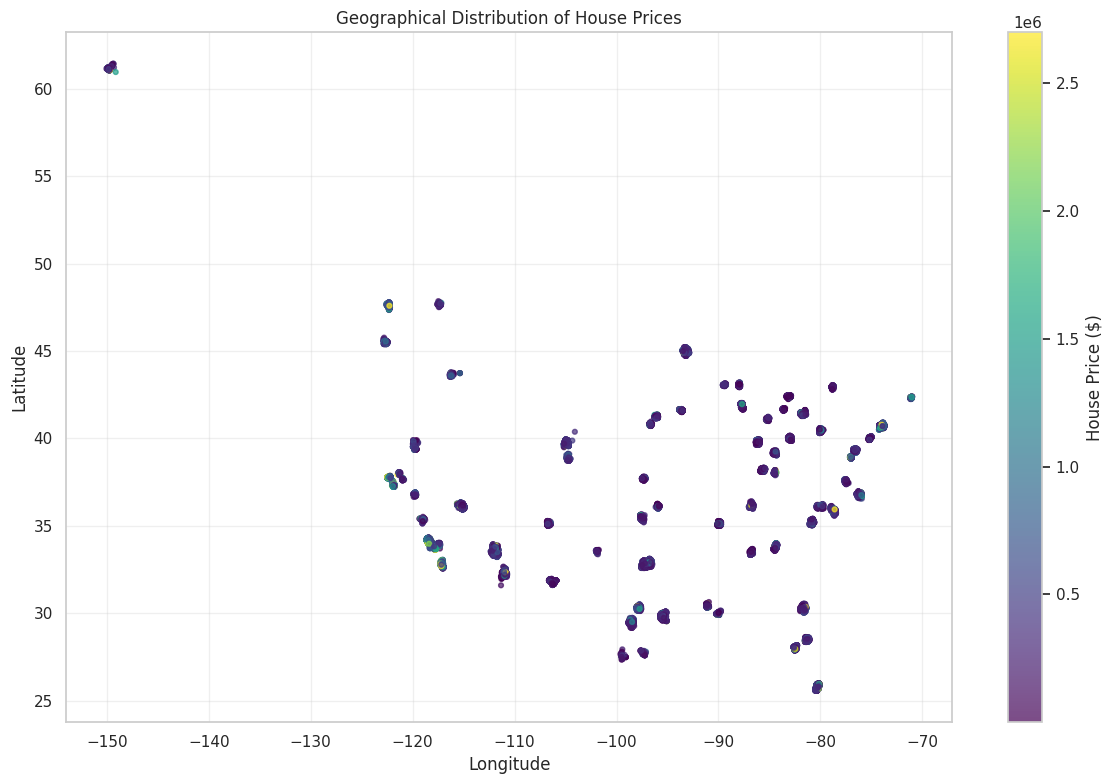

In [10]:
"""
Showing the geographical location of the houses using longitude and latitude.
- using different colours to represent house prices
- adjusting the colour scale to make price differences easier to see
"""

location_data = df.dropna(
    subset=['Longitude', 'Latitude', 'Price']
).copy()

location_data = location_data[
    location_data['Price'] > 0
]

plt.figure(figsize=(12, 8))

graph = plt.scatter(
    location_data['Longitude'],
    location_data['Latitude'],
    c=location_data['Price'],
    cmap='viridis',
    vmin=location_data['Price'].min(),
    vmax=location_data['Price'].quantile(0.98),
    s=12,
    alpha=0.7
)

plt.colorbar(graph, label='House Price ($)')

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.title('Geographical Distribution of House Prices')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    '/content/geographical_house_prices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

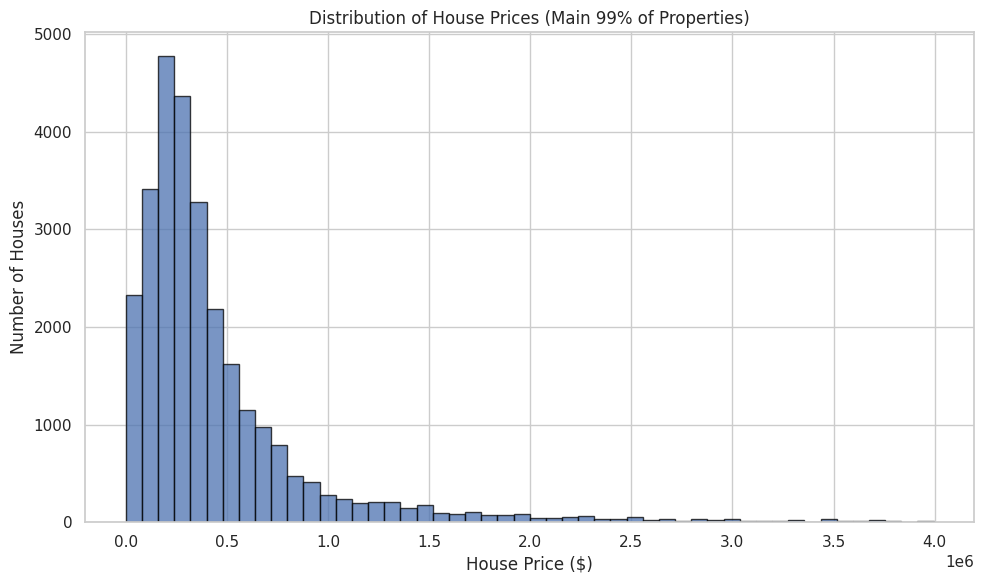

Houses included in graph: 28410
Houses above the displayed price range: 285


In [11]:
"""
Showing the distribution of house prices using a histogram.
- checking how many houses fall into different price ranges
- focusing on the main price distribution to make the graph clearer
"""

price_data = df['Price'].dropna()

# Finding the upper limit for the main price range
upper_limit = price_data.quantile(0.99)

plt.figure(figsize=(10, 6))

plt.hist(
    price_data[price_data <= upper_limit],
    bins=50,
    edgecolor='black',
    alpha=0.75
)

plt.xlabel('House Price ($)')
plt.ylabel('Number of Houses')

plt.title('Distribution of House Prices')

plt.tight_layout()
plt.savefig('/content/house_price_distribution.png', dpi=300)

plt.show()

print("Houses included in graph:", (price_data <= upper_limit).sum())
print("Houses above the displayed price range:", (price_data > upper_limit).sum())

In [15]:
"""
Preparing the important columns for further analysis.
- removing commas and text from the square feet columns
- converting the values into numerical format
- making a separate copy for the analysis
"""

analysis_df = df.copy()

# Converting the columns into numbers
columns_to_convert = ['Sqr Ft', 'Lot Size', ]

for column in columns_to_convert:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(
            r'[^0-9.]', '', regex=True
        ),
        errors='coerce'
    )

# Checking the converted columns
display(analysis_df[
    ['Price', 'Sqr Ft', 'Lot Size',]
].head())

,Price,Sqr Ft,Lot Size,Last Sold For
0,895900.0,3447.0,7895.0,NaN
1,247000.0,1767.0,7877.0,NaN
2,44900.0,1232.0,3510.0,NaN
3,959000.0,1417.0,2598.0,532000.0
4,83500.0,440.0,NaN,52000.0


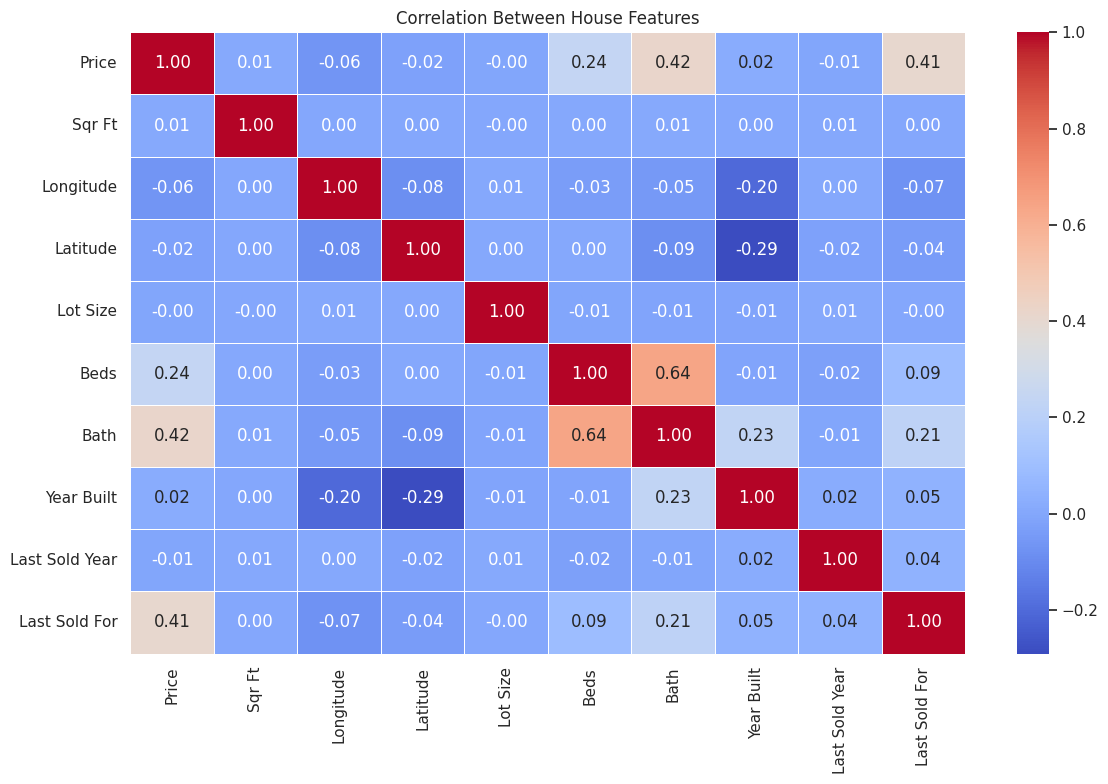

In [14]:
"""
Checking the correlation between the numerical house features.
- comparing the different features with each other
- identifying which features have a stronger relationship with house prices
- displaying the results using a heatmap
"""
1
numerical_data = analysis_df.select_dtypes(
    include=['int64', 'float64']
)

# Removing zipcode because it is a location code
numerical_data = numerical_data.drop(
    columns=['Zipcode'],
    errors='ignore'
)

correlation = numerical_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between House Features')
plt.tight_layout()

plt.savefig(
    '/content/house_feature_correlation.png',
    dpi=300
)

plt.show()

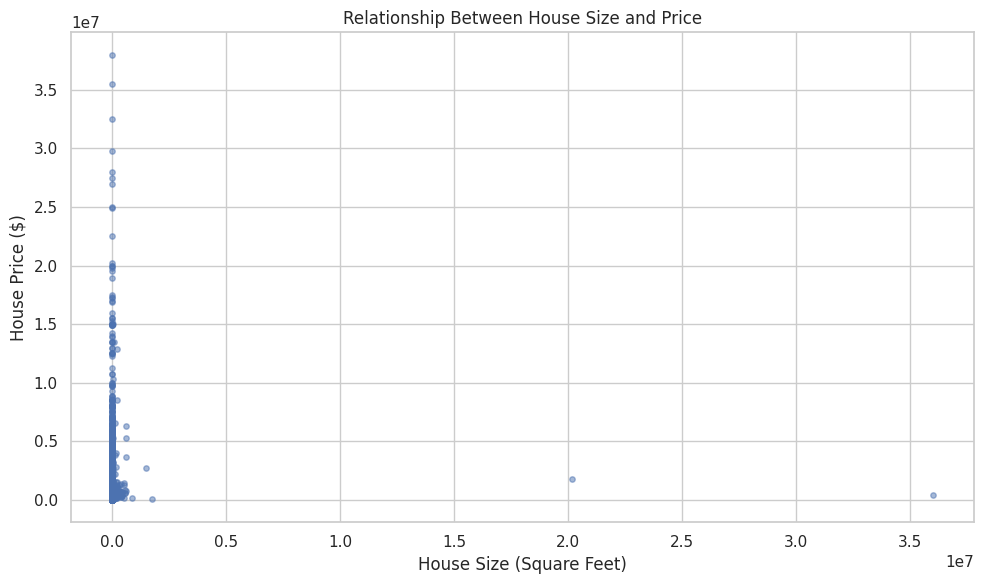

In [13]:
"""
Comparing house prices with the size of the property.
- using square footage to compare the size of houses
- checking whether larger houses generally have higher prices
"""

plot_data = analysis_df.dropna(
    subset=['Sqr Ft', 'Price']
)

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data['Sqr Ft'],
    plot_data['Price'],
    alpha=0.5,
    s=15
)

plt.xlabel('House Size (Square Feet)')
plt.ylabel('House Price ($)')

plt.title('Relationship Between House Size and Price')

plt.tight_layout()
plt.savefig('/content/house_size_vs_price.png', dpi=300)

plt.show()

In [ ]:
check weather this one needed or not later.

In [17]:
"""
Checking the house sizes to find any unusual values.
- looking at the largest square footage values
- checking the overall size of the properties
- identifying possible incorrect or extreme records
"""

print("Square footage statistics:")
display(analysis_df['Sqr Ft'].describe())

print("\nLargest house sizes:")
display(
    analysis_df.nlargest(15, 'Sqr Ft')[
        ['Price', 'Sqr Ft', 'Beds', 'Bath', 'City', 'State']
    ]
)

Square footage statistics:


,Sqr Ft
count,2.778600e+04
mean,5.082979e+03
std,2.484791e+05
min,1.000000e+00
25%,1.286000e+03
50%,1.800000e+03
75%,2.544000e+03
max,3.600380e+07



Largest house sizes:


,Price,Sqr Ft,Beds,Bath,City,State
29728,399000.0,36003799.0,4.0,4.0,Germantown,TN
2107,1750000.0,20168280.0,NaN,NaN,Vegas,NV
28771,90000.0,1745014.0,NaN,NaN,Tucson,AZ
27276,2690000.0,1494979.0,NaN,NaN,Las Vegas,NV
11114,149500.0,895419.0,NaN,NaN,San Antonio,TX
27659,6300000.0,617569.0,2.0,2.0,New York,NY
18616,3650000.0,608532.0,2.0,3.0,New York,NY
16637,5295000.0,600613.0,3.0,3.0,New York,NY
8505,765000.0,593599.0,1.0,1.0,Brooklyn,NY
11206,810000.0,566824.0,1.0,1.0,New York,NY


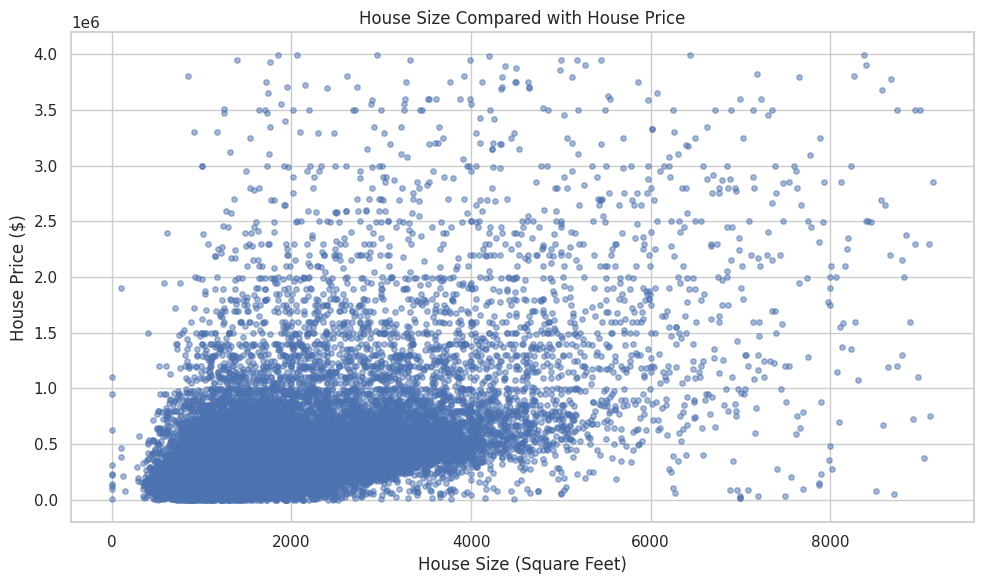

In [16]:
"""
Showing the relationship between house size and price more clearly.
- removing extreme values from this graph only
- comparing the size of houses with their prices
"""

plot_data = analysis_df.dropna(
    subset=['Sqr Ft', 'Price']
).copy()

# Finding the main price and size ranges
size_limit = plot_data['Sqr Ft'].quantile(0.99)
price_limit = plot_data['Price'].quantile(0.99)

# Selecting the main range for the graph
plot_data = plot_data[
    (plot_data['Sqr Ft'] <= size_limit) &
    (plot_data['Price'] <= price_limit)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data['Sqr Ft'],
    plot_data['Price'],
    alpha=0.5,
    s=15
)

plt.xlabel('House Size (Square Feet)')
plt.ylabel('House Price ($)')

plt.title('House Size Compared with House Price')

plt.tight_layout()
plt.savefig('/content/house_size_vs_price.png', dpi=300)

plt.show()

this one needed to done before making graph

In [18]:
"""
Checking the dataset for missing values and duplicate records.
- finding how many values are missing in each column
- checking whether any records are repeated
"""

print("Missing values in each column:")
display(analysis_df.isnull().sum())

print("\nTotal missing values:")
print(analysis_df.isnull().sum().sum())

print("\nNumber of duplicate records:")
print(analysis_df.duplicated().sum())

Missing values in each column:


,0
Price,1311
Sqr Ft,2220
Longitude,0
Latitude,0
Lot Size,4516
Beds,2586
Bath,2510
Year Built,3748
Last Sold Year,15793
Last Sold For,15793



Total missing values:
48480

Number of duplicate records:
9


no need this code section

In [19]:
"""
Checking the range of the numerical columns.
- looking at the minimum and maximum values
- identifying values which may need further checking
"""

numerical_columns = [
    'Price',
    'Sqr Ft',
    'Lot Size',
    'Beds',
    'Bath',
    'Year Built'
]

display(analysis_df[numerical_columns].describe())

,Price,Sqr Ft,Lot Size,Beds,Bath,Year Built
count,2.869500e+04,2.778600e+04,2.549000e+04,27420.000000,27496.000000,26258.000000
mean,5.330534e+05,5.082979e+03,5.380060e+03,3.288658,2.578688,1973.140224
std,1.160391e+06,2.484791e+05,2.291899e+05,1.472238,1.448891,34.512400
min,1.000000e+00,1.000000e+00,2.500000e-01,1.000000,0.750000,1800.000000
25%,1.824995e+05,1.286000e+03,1.972500e+00,3.000000,2.000000,1950.000000
50%,3.050000e+05,1.800000e+03,3.920000e+03,3.000000,2.000000,1978.000000
75%,5.350000e+05,2.544000e+03,6.882000e+03,4.000000,3.000000,2004.000000
max,6.000000e+07,3.600380e+07,3.659040e+07,65.000000,98.000000,2019.000000


In [20]:
"""
Creating a copy of the original sheet for data cleaning.
- keeping the original data unchanged
- making changes only in the new sheet
- removing duplicate records and houses without prices
- removing columns which are not needed for prediction
"""

# Keeping the original sheet
original_sheet = analysis_df.copy(deep=True)

# Creating a new sheet for cleaning
new_sheet = original_sheet.copy(deep=True)

# Removing duplicate records
new_sheet = new_sheet.drop_duplicates()

# Removing houses without recorded prices
new_sheet = new_sheet.dropna(subset=['Price']) #y

# Removing previous sale information
new_sheet = new_sheet.drop(
    columns=['Last Sold Year', 'Last Sold For'] #y
)

print("Original sheet shape:", original_sheet.shape)
print("New sheet shape:", new_sheet.shape)

print("\nMissing values in the new sheet:")
display(new_sheet.isnull().sum())

Original sheet shape: (30006, 15)
New sheet shape: (28689, 13)

Missing values in the new sheet:


,0
Price,0
Sqr Ft,2203
Longitude,0
Latitude,0
Lot Size,3779
Beds,2534
Bath,2468
Year Built,2927
Address,0
City,0


In [21]:
"""
Comparing the original sheet with the new sheet.
- checking the number of rows and columns
- making sure the original data has not been changed
"""

print("Original sheet:", original_sheet.shape)
print("New sheet:", new_sheet.shape)

print("\nOriginal sheet:")
display(original_sheet.head(3))

print("\nNew sheet after cleaning:")
display(new_sheet.head(3))

Original sheet: (30006, 15)
New sheet: (28689, 13)

Original sheet:


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,895900.0,3447.0,-112.081985,33.560055,7895.0,4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000.0,1767.0,-96.676250,32.829227,7877.0,3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900.0,1232.0,-78.825190,42.913000,3510.0,3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"



New sheet after cleaning:


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Address,City,State,Zipcode,Address Full
0,895900.0,3447.0,-112.081985,33.560055,7895.0,4.0,4.5,2019.0,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000.0,1767.0,-96.676250,32.829227,7877.0,3.0,2.0,1954.0,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900.0,1232.0,-78.825190,42.913000,3510.0,3.0,1.0,1900.0,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"


In [22]:
"""
Handling missing values in the numerical columns.
- filling missing values using the median
- keeping the existing values unchanged
- preparing the numerical data for machine learning
"""

numerical_columns = [
    'Sqr Ft',
    'Lot Size',
    'Beds',
    'Bath',
    'Year Built'
]

imputer = SimpleImputer(strategy='median')

new_sheet[numerical_columns] = imputer.fit_transform(
    new_sheet[numerical_columns]
)

print("Missing values after filling:")
display(new_sheet[numerical_columns].isnull().sum())

Missing values after filling:


,0
Sqr Ft,0
Lot Size,0
Beds,0
Bath,0
Year Built,0


no need to fill any missing values

In [23]:
"""
Preparing the data for machine learning.
- creating a separate set of features and target values
- splitting the data into training and testing parts
- filling missing values using the training data
"""

# Creating a fresh copy for machine learning
new_sheet = original_sheet.copy(deep=True)

new_sheet = new_sheet.drop_duplicates()
new_sheet = new_sheet.dropna(subset=['Price'])

new_sheet = new_sheet.drop(
    columns=['Last Sold Year', 'Last Sold For']
)

# Selecting the features for predicting house prices
feature_columns = [
    'Sqr Ft',
    'Longitude',
    'Latitude',
    'Lot Size',
    'Beds',
    'Bath',
    'Year Built'
]

X = new_sheet[feature_columns]
y = new_sheet['Price']

# Splitting the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Filling missing values using the training data
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=feature_columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=feature_columns,
    index=X_test.index
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

Training data: (22951, 7)
Testing data: (5738, 7)

Missing values in training data:
0

Missing values in testing data:
0


In [24]:
"""
Building a linear regression model to predict house prices.
- training the model using the training data
- making predictions using the testing data
- checking how accurate the predictions are
"""

# Creating the linear regression model
linear_model = LinearRegression()

# Training the model
linear_model.fit(X_train, y_train)

# Predicting house prices
y_pred = linear_model.predict(X_test)

# Checking the model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Linear Regression Results
-------------------------
Mean Absolute Error: 372881.25
Mean Squared Error: 1232202812958.31
Root Mean Squared Error: 1110046.31
R2 Score: 0.1545


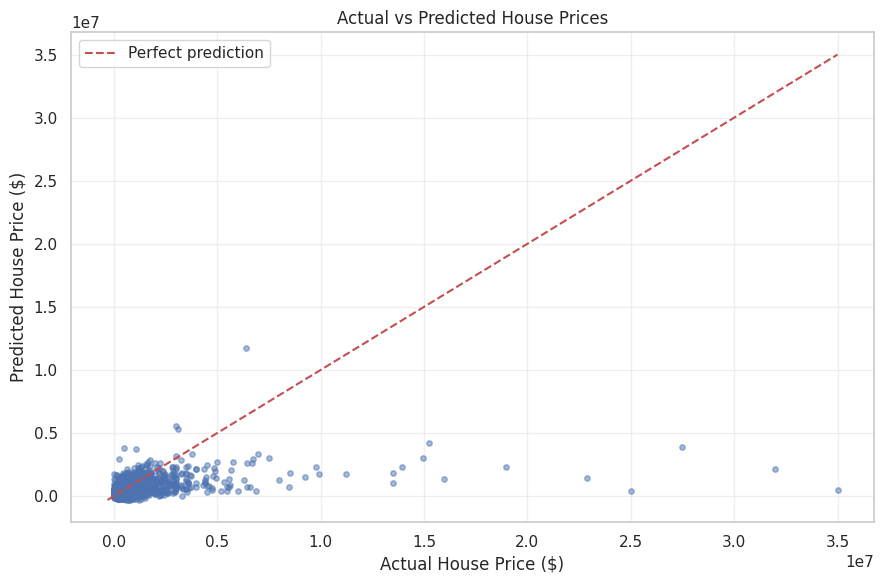

In [25]:
"""
Comparing the actual house prices with the predicted prices.
- showing the actual and predicted values on a graph
- checking how close the predictions are to the real prices
"""

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    s=15
)

# Adding a line to show perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect prediction'
)

plt.xlabel('Actual House Price ($)')
plt.ylabel('Predicted House Price ($)')

plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('/content/actual_vs_predicted.png', dpi=300)

plt.show()

In [27]:
"""
Building a random forest regression model.
- training the model using the same training data
- predicting house prices using the testing data
- comparing its performance with linear regression
"""

# Creating the random forest model
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Training the model
forest_model.fit(X_train, y_train)

# Predicting house prices
forest_pred = forest_model.predict(X_test)

# Checking the model performance
forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))
forest_r2 = r2_score(y_test, forest_pred)

print("Random Forest Regression Results")
print("--------------------------------")
print("Mean Absolute Error:", round(forest_mae, 2))
print("Root Mean Squared Error:", round(forest_rmse, 2))
print("R2 Score:", round(forest_r2, 4))

Random Forest Regression Results
--------------------------------
Mean Absolute Error: 199449.44
Root Mean Squared Error: 865026.82
R2 Score: 0.4866


In [28]:
"""
Comparing the two regression models.
- checking which model has lower prediction errors
- comparing their R2 scores
- identifying the better performing model
"""

model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, forest_mae],
    'RMSE': [rmse, forest_rmse],
    'R2 Score': [r2, forest_r2]
})

display(model_results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,372881.250943,1.110046e+06,0.154492
1,Random Forest,199449.436421,8.650268e+05,0.486554


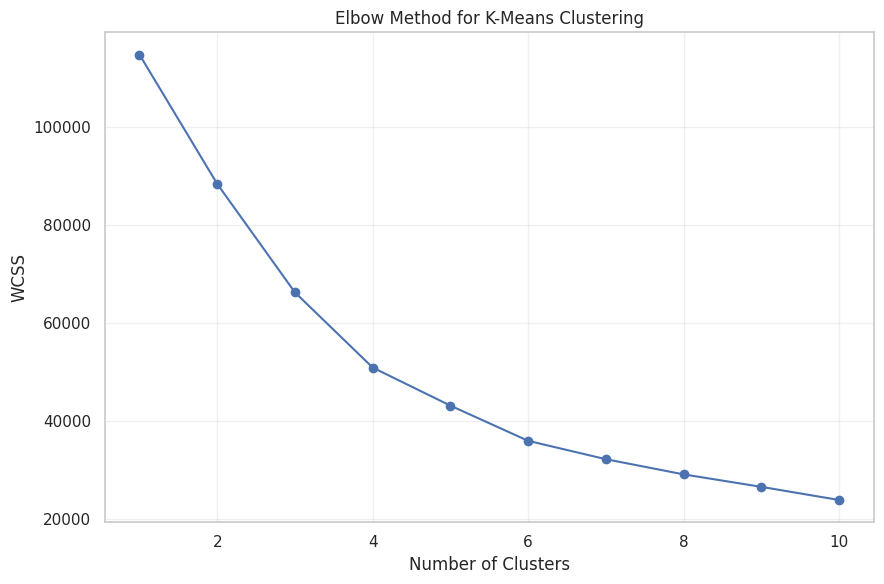

In [29]:
"""
Finding the suitable number of clusters for the house data.
- using the elbow method
- checking how the clustering results change with different numbers of groups
"""

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Selecting the features for clustering
cluster_data = new_sheet[
    ['Price', 'Sqr Ft', 'Beds', 'Bath']
].copy()

# Filling any missing values
cluster_data = cluster_data.fillna(
    cluster_data.median()
)

# Scaling the data
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

# Checking different numbers of clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

# Displaying the elbow graph
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.title('Elbow Method for K-Means Clustering')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('/content/elbow_method.png', dpi=300)

plt.show()

In [30]:
"""
Grouping houses using the K-Means clustering method.
- creating four different groups
- assigning each house to a cluster
- checking the number of houses in each group
"""

# Creating the K-Means model
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assigning houses to clusters
cluster_data['Cluster'] = kmeans_model.fit_predict(
    scaled_data
)

# Checking the number of houses in each group
print("Number of houses in each cluster:")
display(cluster_data['Cluster'].value_counts().sort_index())

Number of houses in each cluster:


,count
Cluster,
0,20266
1,8337
2,84
3,2


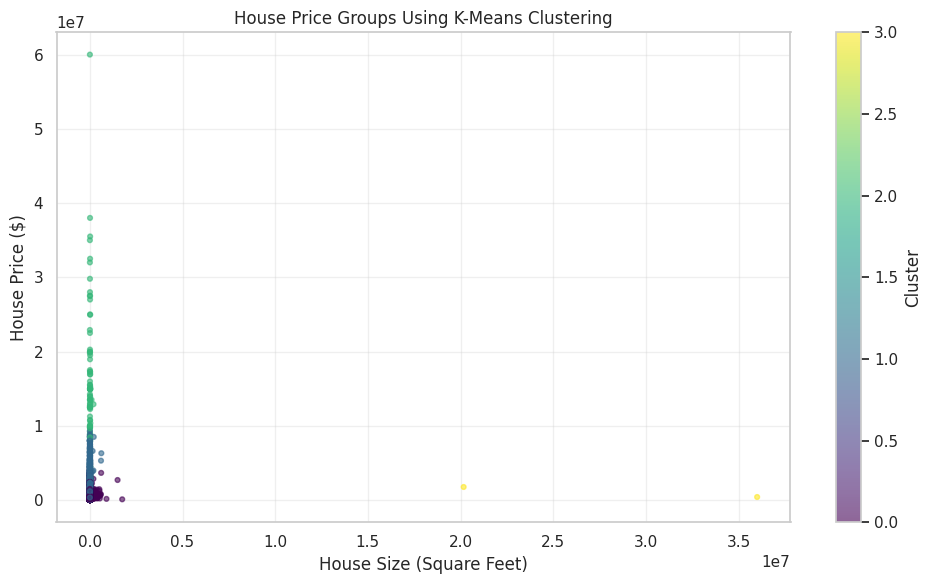

In [31]:
"""
Displaying the four house groups using a scatter graph.
- using different colours for each cluster
- comparing house sizes and prices
- understanding how the houses are grouped
"""

plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_data['Sqr Ft'],
    cluster_data['Price'],
    c=cluster_data['Cluster'],
    cmap='viridis',
    s=12,
    alpha=0.6
)

plt.xlabel('House Size (Square Feet)')
plt.ylabel('House Price ($)')

plt.title('House Price Groups Using K-Means Clustering')

plt.colorbar(label='Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('/content/house_price_clusters.png', dpi=300)

plt.show()

In [32]:
"""
Checking unusually large values in the house dataset.
- finding the largest house sizes and prices
- checking the 99th percentile
- identifying values which may affect clustering
"""

print("House size statistics:")
display(cluster_data['Sqr Ft'].describe(
    percentiles=[0.90, 0.95, 0.99]
))

print("\nHouse price statistics:")
display(cluster_data['Price'].describe(
    percentiles=[0.90, 0.95, 0.99]
))

print("\n10 largest house sizes:")
display(
    cluster_data.nlargest(10, 'Sqr Ft')[
        ['Price', 'Sqr Ft', 'Beds', 'Bath']
    ]
)

House size statistics:


,Sqr Ft
count,2.868900e+04
mean,4.948114e+03
std,2.445366e+05
min,1.000000e+00
50%,1.775000e+03
90%,3.477000e+03
95%,4.418600e+03
99%,8.800000e+03
max,3.600380e+07



House price statistics:


,Price
count,2.868900e+04
mean,5.331068e+05
std,1.160505e+06
min,1.000000e+00
50%,3.050000e+05
90%,9.750000e+05
95%,1.554598e+06
99%,3.995000e+06
max,6.000000e+07



10 largest house sizes:


,Price,Sqr Ft,Beds,Bath
29728,399000.0,36003799.0,4.0,4.0
2107,1750000.0,20168280.0,3.0,2.0
28771,90000.0,1745014.0,3.0,2.0
27276,2690000.0,1494979.0,3.0,2.0
11114,149500.0,895419.0,3.0,2.0
27659,6300000.0,617569.0,2.0,2.0
18616,3650000.0,608532.0,2.0,3.0
16637,5295000.0,600613.0,3.0,3.0
8505,765000.0,593599.0,1.0,1.0
11206,810000.0,566824.0,1.0,1.0


In [33]:
"""
Preparing the house data for better clustering.
- checking the upper 99 percent range
- removing extremely large values for this analysis
- keeping the original dataset unchanged
"""

# Finding the upper limits
size_limit = cluster_data['Sqr Ft'].quantile(0.99)
price_limit = cluster_data['Price'].quantile(0.99)

# Creating a separate dataset
cluster_sheet = cluster_data[
    (cluster_data['Sqr Ft'] <= size_limit) &
    (cluster_data['Price'] <= price_limit)
].copy()

print("House size limit:", size_limit)
print("House price limit:", price_limit)

print("\nOriginal number of houses:", len(cluster_data))
print("Houses used for clustering:", len(cluster_sheet))
print("Houses removed:", len(cluster_data) - len(cluster_sheet))

House size limit: 8800.0
House price limit: 3995000.0

Original number of houses: 28689
Houses used for clustering: 28180
Houses removed: 509


In [34]:
"""
Grouping the houses again after removing extreme values.
- scaling the selected house features
- creating four clusters using K-Means
- checking the number of houses in each group
"""

# Selecting the features
cluster_features = cluster_sheet[
    ['Price', 'Sqr Ft', 'Beds', 'Bath']
]

# Scaling the data
scaler = StandardScaler()
scaled_cluster_data = scaler.fit_transform(cluster_features)

# Creating the K-Means model
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assigning houses to groups
cluster_sheet['Cluster'] = kmeans_model.fit_predict(
    scaled_cluster_data
)

print("Number of houses in each cluster:")
display(
    cluster_sheet['Cluster'].value_counts().sort_index()
)

Number of houses in each cluster:


,count
Cluster,
0,6752
1,1336
2,6427
3,13665


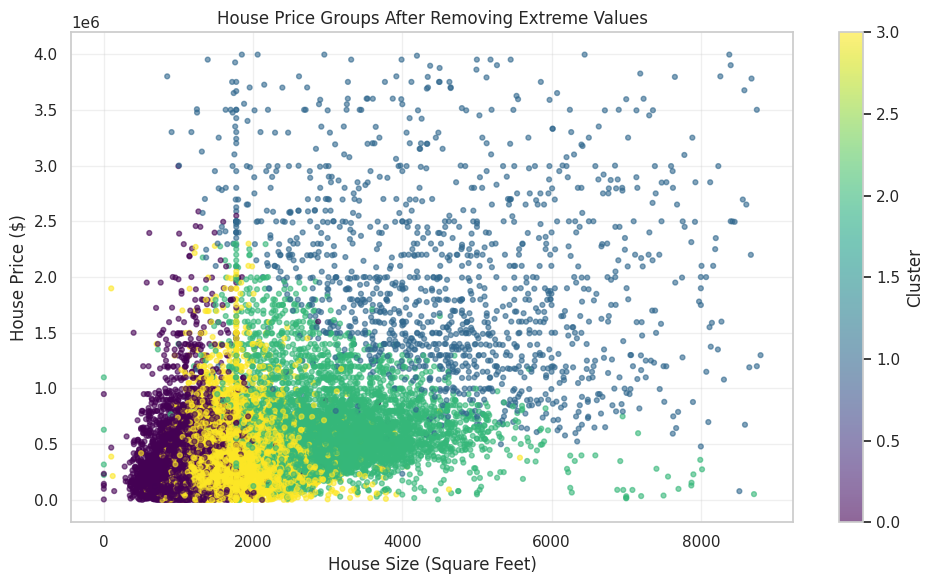

In [35]:
"""
Showing the house groups after removing extreme values.
- comparing house sizes and prices
- displaying each cluster using a different colour
- making the groups easier to understand
"""

plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_sheet['Sqr Ft'],
    cluster_sheet['Price'],
    c=cluster_sheet['Cluster'],
    cmap='viridis',
    s=12,
    alpha=0.6
)

plt.xlabel('House Size (Square Feet)')
plt.ylabel('House Price ($)')

plt.title('House Price Groups After Removing Extreme Values')

plt.colorbar(label='Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('/content/improved_house_clusters.png', dpi=300)

plt.show()

In [36]:
"""
Checking the average values of the four house groups.
- comparing the average house prices
- checking the average house sizes and bedrooms
- understanding the differences between each group
"""

cluster_summary = cluster_sheet.groupby('Cluster').agg({
    'Price': 'mean',
    'Sqr Ft': 'mean',
    'Beds': 'mean',
    'Bath': 'mean'
}).round(2)

print("Average details of each house group:")
display(cluster_summary)

Average details of each house group:


,Price,Sqr Ft,Beds,Bath
Cluster,,,,
0,298226.83,1094.46,2.04,1.42
1,1951211.83,4608.69,4.89,5.02
2,586304.46,2980.06,4.24,3.48
3,306510.41,1744.54,3.19,2.28


In [37]:
"""
Checking how well the houses are grouped.
- calculating the silhouette score
- checking how closely houses fit within their clusters
"""

silhouette = silhouette_score(
    scaled_cluster_data,
    cluster_sheet['Cluster'],
    sample_size=3000,
    random_state=42
)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.2793


In [38]:
"""
Preparing the data for house price classification.
- using the cluster groups as the target categories
- selecting house features without using the actual prices
- splitting the data into training and testing parts
- filling missing values using the training data
"""

# Selecting the house features
X_class = new_sheet.loc[
    cluster_sheet.index, feature_columns
].copy()

# Selecting the cluster groups
y_class = cluster_sheet['Cluster']

# Splitting the data
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

# Filling missing values
class_imputer = SimpleImputer(strategy='median')

X_train_class = pd.DataFrame(
    class_imputer.fit_transform(X_train_class),
    columns=feature_columns,
    index=X_train_class.index
)

X_test_class = pd.DataFrame(
    class_imputer.transform(X_test_class),
    columns=feature_columns,
    index=X_test_class.index
)

print("Training data:", X_train_class.shape)
print("Testing data:", X_test_class.shape)

print("\nTraining category distribution:")
display(y_train_class.value_counts().sort_index())

Training data: (22544, 7)
Testing data: (5636, 7)

Training category distribution:


,count
Cluster,
0,5401
1,1069
2,5142
3,10932


In [39]:
"""
Building a decision tree classification model.
- training the model using the house features
- predicting the house price groups
- checking the model accuracy
"""

# Creating the decision tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

# Training the model
tree_model.fit(X_train_class, y_train_class)

# Predicting the house categories
tree_pred = tree_model.predict(X_test_class)

# Checking the results
tree_accuracy = accuracy_score(y_test_class, tree_pred)

print("Decision Tree Classification Results")
print("------------------------------------")
print("Accuracy:", round(tree_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test_class, tree_pred))

Decision Tree Classification Results
------------------------------------
Accuracy: 0.9454

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1351
           1       0.75      0.54      0.62       267
           2       0.89      0.90      0.89      1285
           3       0.96      0.98      0.97      2733

    accuracy                           0.95      5636
   macro avg       0.90      0.85      0.87      5636
weighted avg       0.94      0.95      0.94      5636



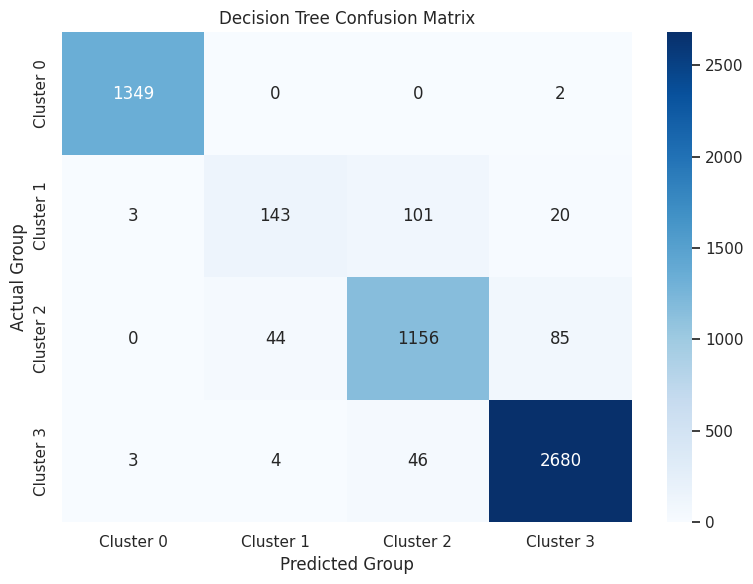

In [40]:
"""
Checking the decision tree classification results.
- comparing the actual groups with the predicted groups
- identifying correctly and incorrectly classified houses
- displaying the results using a confusion matrix
"""

cm = confusion_matrix(y_test_class, tree_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3'],
    yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3']
)

plt.xlabel('Predicted Group')
plt.ylabel('Actual Group')

plt.title('Decision Tree Confusion Matrix')

plt.tight_layout()
plt.savefig('/content/decision_tree_confusion_matrix.png', dpi=300)

plt.show()

In [41]:
"""
Building a random forest classification model.
- training the model using the same training data
- predicting the house groups
- comparing its accuracy with the decision tree model
"""

# Creating the random forest classifier
forest_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Training the model
forest_classifier.fit(X_train_class, y_train_class)

# Predicting the house groups
forest_class_pred = forest_classifier.predict(X_test_class)

# Checking the accuracy
forest_class_accuracy = accuracy_score(
    y_test_class,
    forest_class_pred
)

print("Random Forest Classification Results")
print("------------------------------------")
print("Accuracy:", round(forest_class_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test_class, forest_class_pred))

Random Forest Classification Results
------------------------------------
Accuracy: 0.9565

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1351
           1       0.86      0.63      0.72       267
           2       0.91      0.92      0.92      1285
           3       0.97      0.99      0.98      2733

    accuracy                           0.96      5636
   macro avg       0.93      0.88      0.90      5636
weighted avg       0.96      0.96      0.95      5636



In [42]:
"""
Comparing the decision tree and random forest classifiers.
- checking the accuracy of both models
- identifying which model performs better
"""

classification_results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [tree_accuracy, forest_class_accuracy]
})

display(
    classification_results.sort_values(
        by='Accuracy',
        ascending=False
    )
)

,Model,Accuracy
1,Random Forest,0.956529
0,Decision Tree,0.945351


,Feature,Importance
0,Sqr Ft,0.303540
5,Bath,0.298103
4,Beds,0.256709
1,Longitude,0.040100
6,Year Built,0.035189
2,Latitude,0.033825
3,Lot Size,0.032533


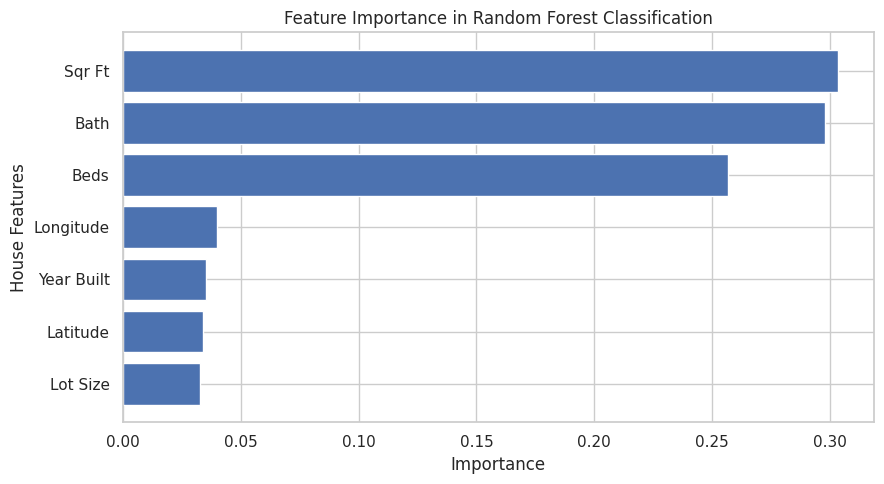

In [43]:
"""
Checking which house features are important for classification.
- comparing the importance of each feature
- identifying which features contribute more to the predictions
"""

feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': forest_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('House Features')

plt.title('Feature Importance in Random Forest Classification')

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig('/content/classification_feature_importance.png', dpi=300)

plt.show()